# Practical 6: Setting up Apache Airflow and Creating a DAG

**Name:** Vedant Vinod Rakshe

**Aim:** To configure a Directed Acyclic Graph (DAG) in Apache Airflow that runs daily and executes sequentially dependent tasks: a start notifier, an extraction script, and a pipeline success logger.

Airflow runs on Linux / macOS / WSL2 / Google Colab. This notebook installs Airflow, writes the extraction script (Practical 5) and the DAG file into `~/airflow`, validates the DAG and draws its task graph.

## Task 1: Install Apache Airflow

In [ ]:
%pip install -q apache-airflow

## Task 2: Write the Extraction Script (from Practical 5) and the DAG File

In [1]:
import os
print("Name: Vedant Vinod Rakshe")

extraction_code = r'''
# Name: Vedant Vinod Rakshe
# data_extraction.py  -  ETL: REST API + flat CSV file -> cleaned merged dataset
print("Name: Vedant Vinod Rakshe")
import re
import pandas as pd
import requests

API_URL = "https://jsonplaceholder.typicode.com/users"

# Cached copy of the API response, used only if the API cannot be reached
FALLBACK_ROWS = [
    (1, "Leanne Graham", "Sincere@april.biz", "Romaguera-Crona"),
    (2, "Ervin Howell", "Shanna@melissa.tv", "Deckow-Crist"),
    (3, "Clementine Bauch", "Nathan@yesenia.net", "Romaguera-Jacobson"),
    (4, "Patricia Lebsack", "Julianne.OConner@kory.org", "Robel-Corkery"),
    (5, "Chelsey Dietrich", "Lucio_Hettinger@annie.ca", "Keebler LLC"),
    (6, "Mrs. Dennis Schulist", "Karley_Dach@jasper.net", "Considine-Lockman"),
    (7, "Kurtis Weissnat", "Telly.Hoeger@billy.biz", "Johns Group"),
    (8, "Nicholas Runolfsdottir V", "Sherwood@rosamond.me", "Abernathy Group"),
    (9, "Glenna Reichert", "Chaim_McDermott@dana.io", "Yost and Sons"),
    (10, "Clementina DuBuque", "Rey.Padberg@karina.biz", "Hoeger LLC"),
]
FALLBACK = [{"id": i, "name": n, "email": e, "company": {"name": c}}
            for i, n, e, c in FALLBACK_ROWS]

def extract_api_data(url):
    """Fetches data from a REST API and returns a flat DataFrame."""
    try:
        response = requests.get(url, timeout=10)
        response.raise_for_status()
        print("Source: live REST API")
        return pd.json_normalize(response.json())
    except requests.exceptions.RequestException as e:
        print(f"Live API not reachable ({type(e).__name__}) - using cached copy of the same data")
        return pd.json_normalize(FALLBACK)

def extract_csv_data(file_path):
    """Reads a flat CSV file."""
    try:
        return pd.read_csv(file_path)
    except FileNotFoundError as e:
        print(f"File Error: {e}")
        return pd.DataFrame()

def clean_users(df):
    """Select columns, rename, tidy text and validate e-mail addresses."""
    df = df[["id", "name", "email", "company.name"]].rename(columns={"company.name": "company"})
    df["name"] = df["name"].str.strip()
    df["email"] = df["email"].str.strip().str.lower()
    df = df.drop_duplicates(subset="id")
    valid = df["email"].str.match(r"^[\w.+-]+@[\w-]+\.[\w.]+$")
    print("Invalid e-mails removed:", (~valid).sum())
    return df[valid]

if __name__ == "__main__":
    # 1. API extraction + cleaning
    api_df = clean_users(extract_api_data(API_URL))
    print("\nAPI data (cleaned):\n", api_df.head(), end="\n\n")

    # 2. Flat file extraction (create the locations.csv file for this lab)
    csv_file = "locations.csv"
    pd.DataFrame({
        "id": list(range(1, 11)),
        "city": ["New York", "London", "Paris", "Tokyo", "Berlin",
                 "Delhi", "Sydney", "Moscow", "Cairo", "Beijing"],
        "country": ["USA", "UK", "France", "Japan", "Germany",
                    "India", "Australia", "Russia", "Egypt", "China"],
    }).to_csv(csv_file, index=False)
    csv_df = extract_csv_data(csv_file)
    print("CSV data:\n", csv_df.head(), end="\n\n")

    # 3. Transformation & merging
    if not api_df.empty and not csv_df.empty:
        merged_df = pd.merge(api_df, csv_df, on="id", how="inner")
        print("--- Merged ETL Pipeline Data View ---")
        print(merged_df.to_string(index=False))
        missing = int(merged_df.isnull().sum().sum())
        print("\nShape:", merged_df.shape, "| Missing values:", missing)
        merged_df.to_csv("cleaned_warehouse_profiles.csv", index=False)
        print("\nData successfully saved to 'cleaned_warehouse_profiles.csv'")
'''

dag_code = r'''
# Name: Vedant Vinod Rakshe
# File: ~/airflow/dags/data_pipeline_dag.py
from datetime import datetime, timedelta
from airflow import DAG

try:                                   # Airflow 3.x import paths
    from airflow.providers.standard.operators.bash import BashOperator
    from airflow.providers.standard.operators.empty import EmptyOperator
except ImportError:                    # Airflow 2.x import paths
    from airflow.operators.bash import BashOperator
    from airflow.operators.empty import EmptyOperator

# Default arguments for the workflow pipeline execution
default_args = {
    "owner": "data_engineering_lab",
    "depends_on_past": False,
    "retries": 1,
    "retry_delay": timedelta(minutes=5),
}

# Define the DAG context
with DAG(
    dag_id="university_etl_orchestration",
    default_args=default_args,
    description="Lab assignment for API and Flat File ETL orchestration",
    start_date=datetime(2026, 1, 1),
    schedule=timedelta(days=1),        # run once every day
    catchup=False,
) as dag:

    # Task 1: Pipeline init anchor (start notifier)
    start_pipeline = EmptyOperator(task_id="start_pipeline")

    # Task 2: Run the Python extraction script from Practical 5
    execute_extraction = BashOperator(
        task_id="run_extraction_script",
        bash_command="cd ~/airflow/scripts && python3 data_extraction.py",
    )

    # Task 3: Finalize and log success
    pipeline_complete = BashOperator(
        task_id="log_pipeline_success",
        bash_command='echo "ETL Execution completed successfully at $(date)"',
    )

    # Sequential dependencies: start -> extract -> log
    start_pipeline >> execute_extraction >> pipeline_complete
'''

for folder in ("dags", "scripts"):
    os.makedirs(os.path.expanduser(f"~/airflow/{folder}"), exist_ok=True)
open(os.path.expanduser("~/airflow/scripts/data_extraction.py"), "w").write(extraction_code)
open(os.path.expanduser("~/airflow/dags/data_pipeline_dag.py"), "w").write(dag_code)
print("Written: ~/airflow/scripts/data_extraction.py")
print("Written: ~/airflow/dags/data_pipeline_dag.py")

Name: Vedant Vinod Rakshe
Written: ~/airflow/scripts/data_extraction.py
Written: ~/airflow/dags/data_pipeline_dag.py


## Task 3: Validate the DAG Structure

In [2]:
# Check that Airflow can parse the DAG and that the dependencies are correct
import os
from airflow.models import DagBag

print("Name: Vedant Vinod Rakshe")

bag = DagBag(os.path.expanduser("~/airflow/dags"), include_examples=False)
print("DAG files parsed  :", len(bag.dags))
print("Import errors     :", bag.import_errors or "None")

dag = bag.get_dag("university_etl_orchestration")
print("DAG id            :", dag.dag_id)
print("Schedule          :", dag.schedule)
print("Catchup           :", dag.catchup)
print("Number of tasks   :", len(dag.tasks))
print("\nTask dependencies:")
for t in dag.tasks:
    print(f"  {t.task_id:<22} ({type(t).__name__:<14}) -> {sorted(t.downstream_task_ids) or 'end'}")

Name: Vedant Vinod Rakshe
DAG files parsed  : 1
Import errors     : None
DAG id            : university_etl_orchestration
Schedule          : 1 day, 0:00:00
Catchup           : False
Number of tasks   : 3

Task dependencies:
  start_pipeline         (EmptyOperator ) -> ['run_extraction_script']
  run_extraction_script  (BashOperator  ) -> ['log_pipeline_success']
  log_pipeline_success   (BashOperator  ) -> end


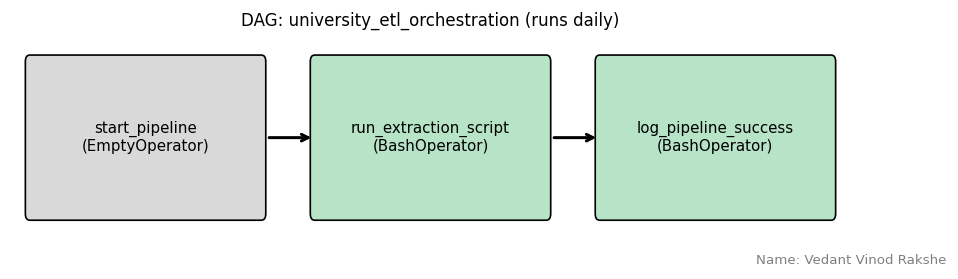

In [ ]:
import matplotlib.pyplot as plt
from matplotlib.patches import FancyBboxPatch

fig, ax = plt.subplots(figsize=(9, 2.2))
names = ["start_pipeline\n(EmptyOperator)", "run_extraction_script\n(BashOperator)",
         "log_pipeline_success\n(BashOperator)"]
colors = ["#d9d9d9", "#b7e4c7", "#b7e4c7"]
for i, (n, c) in enumerate(zip(names, colors)):
    x = i * 3.2
    ax.add_patch(FancyBboxPatch((x, 0.2), 2.6, 1.2, boxstyle="round,pad=0.05", fc=c, ec="black"))
    ax.text(x + 1.3, 0.8, n, ha="center", va="center", fontsize=9)
    if i < 2:
        ax.annotate("", xy=(x + 3.2, 0.8), xytext=(x + 2.65, 0.8),
                    arrowprops=dict(arrowstyle="->", lw=1.8))
ax.set_xlim(-0.2, 9.2); ax.set_ylim(0, 1.6); ax.axis("off")
ax.set_title("DAG: university_etl_orchestration (runs daily)", fontsize=10)
plt.gcf().text(0.99, 0.005, "Name: Vedant Vinod Rakshe", ha="right", va="bottom", fontsize=8, color="gray")
plt.savefig("p6_dag.png", dpi=120, bbox_inches="tight")

## Task 4: Run the DAG
In a terminal run `airflow standalone`, open http://localhost:8080, unpause `university_etl_orchestration` and trigger it. All three tasks turn green when the run succeeds.

**Conclusion:** An Airflow DAG named university_etl_orchestration was written with three tasks chained in sequence (start_pipeline, run_extraction_script, log_pipeline_success) and scheduled to run once a day. Airflow parsed the DAG without import errors and confirmed the dependency order, so the extraction pipeline is orchestrated automatically instead of being started by hand.